In [3]:
import cv2, numpy as np, matplotlib.pyplot as plt, json, csv, time
from pathlib import Path
print("OpenCV", cv2.__version__)

IMG = Path("data") / "task03_objects.jpg"
RESULTS = Path("results")
W, MIN_AREA, OPEN_K, CLOSE_K, IOU_THR = 800, 300, 5, 9, 0.5

img = cv2.imread(str(IMG)); assert img is not None
h0, w0 = img.shape[:2]
img = cv2.resize(img, (W, round(h0 * W / w0)), interpolation=cv2.INTER_AREA)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
H = gray.shape[0]
GT = json.loads((RESULTS / "task12_gt_boxes.json").read_text())["boxes"]
print("image", gray.shape, "| ground-truth objects:", len(GT))

K_O = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (OPEN_K, OPEN_K))
K_C = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (CLOSE_K, CLOSE_K))

def run(k):
    """Blur (k x k) -> Otsu (inverted) -> open -> close -> contours (area, border filter)."""
    t0 = time.perf_counter()
    b = cv2.GaussianBlur(gray, (k, k), 0) if k > 1 else gray.copy()
    t1 = time.perf_counter()
    T, bw = cv2.threshold(b, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    m = cv2.morphologyEx(cv2.morphologyEx(bw, cv2.MORPH_OPEN, K_O), cv2.MORPH_CLOSE, K_C)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for c in cnts:
        if cv2.contourArea(c) < MIN_AREA: continue
        x, y, w, h = cv2.boundingRect(c)
        if x <= 0 or y <= 0 or x + w >= W - 1 or y + h >= H - 1: continue   # touches the border
        boxes.append((x, y, w, h))
    t2 = time.perf_counter()
    return dict(k=k, T=T, boxes=boxes, blurred=b, mask=m,
                blur_ms=(t1 - t0) * 1000, total_ms=(t2 - t0) * 1000)

def iou(a, b):
    ax, ay, aw, ah = a; bx, by, bw, bh = b
    ix = max(0, min(ax + aw, bx + bw) - max(ax, bx)); iy = max(0, min(ay + ah, by + bh) - max(ay, by))
    inter = ix * iy
    return inter / (aw * ah + bw * bh - inter)

def inside_ratio(d, g):
    """Share of the detection box d that lies inside the GT box g."""
    dx, dy, dw, dh = d; gx, gy, gw, gh = g
    ix = max(0, min(dx + dw, gx + gw) - max(dx, gx)); iy = max(0, min(dy + dh, gy + gh) - max(dy, gy))
    return ix * iy / (dw * dh)

def evaluate(boxes):
    """Counting: detection is true if >= 50 % of it lies inside an unused GT box.
       Precision: mean IoU of the matched pairs."""
    used, labels, ious = set(), [], []
    for d in boxes:
        cands = [(inside_ratio(d, g), iou(d, g), j) for j, g in enumerate(GT) if j not in used]
        best = max(cands, default=(0, 0, None))
        if best[0] >= 0.5:
            used.add(best[2]); labels.append("true"); ious.append(best[1])
        else:
            labels.append("false")
    tp = labels.count("true"); fp = labels.count("false"); fn = len(GT) - tp
    f1 = 2 * tp / (2 * tp + fp + fn) if (tp + fp + fn) else 1.0
    return labels, tp, fp, fn, f1, (float(np.mean(ious)) if ious else 0.0)

def draw(r, labels):
    vis = img.copy()
    for g in GT:
        x, y, w, h = g; cv2.rectangle(vis, (x, y), (x + w, y + h), (255, 0, 0), 1)          # GT: blue, thin
    for (x, y, w, h), lab in zip(r["boxes"], labels):
        cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 200, 0) if lab == "true" else (0, 0, 255), 2)
    return vis

OpenCV 5.0.0
image (600, 800) | ground-truth objects: 9


Cell 2 (check at k = 5, the Task 3 setting

k=5: Otsu T=159 | found 9 | true 9 | false 0 | missed 0 | F1 1.00 | blur 0.23 ms, pipeline 2.7 ms
   box (543, 416, 68, 45)  best IoU 0.60  -> true
   box (199, 350, 79, 86)  best IoU 0.71  -> true
   box (356, 317, 30, 53)  best IoU 0.40  -> true
   box (393, 316, 131, 92)  best IoU 0.70  -> true
   box (102, 274, 86, 39)  best IoU 0.25  -> true
   box (235, 204, 51, 34)  best IoU 0.42  -> true
   box (387, 197, 40, 42)  best IoU 0.62  -> true
   box (491, 126, 114, 110)  best IoU 0.69  -> true
   box (276, 119, 173, 30)  best IoU 0.72  -> true


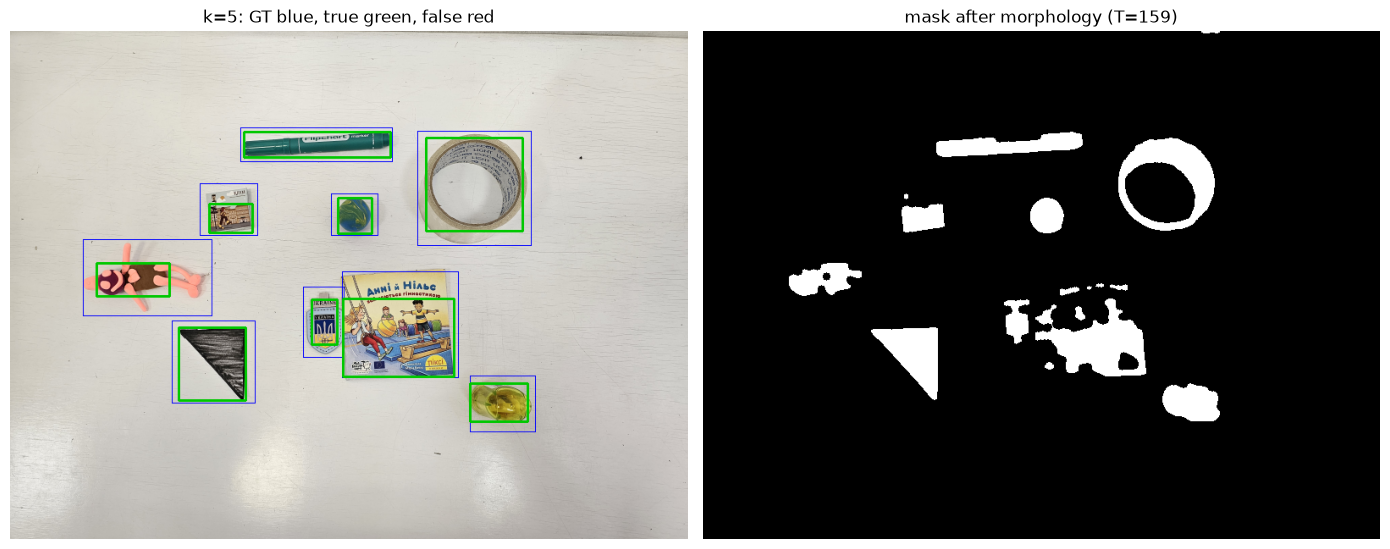

In [4]:
r = run(5)
labels, tp, fp, fn, f1, miou = evaluate(r["boxes"])
print(f"k=5: Otsu T={r['T']:.0f} | found {len(r['boxes'])} | true {tp} | false {fp} | missed {fn} | F1 {f1:.2f}"
      f" | blur {r['blur_ms']:.2f} ms, pipeline {r['total_ms']:.1f} ms")
for d, lab in zip(r["boxes"], labels):
    best = max(iou(d, g) for g in GT)
    print(f"   box {d}  best IoU {best:.2f}  -> {lab}")

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ax[0].imshow(cv2.cvtColor(draw(r, labels), cv2.COLOR_BGR2RGB)); ax[0].set_title("k=5: GT blue, true green, false red")
ax[1].imshow(r["mask"], cmap="gray"); ax[1].set_title(f"mask after morphology (T={r['T']:.0f})")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(RESULTS / "task12_step2_check_k5.png", dpi=100); plt.show()

Steps 3–4: The experiment and the graphs

        k |     sigma |   blur_ms | pipeline_ms |    otsu_T |     found |      true |     false |    missed |        f1 |  mean_iou | sharpness_pct |   psnr_db
        1 |         0 |     0.062 |      5.45 |       151 |         8 |         8 |         0 |         1 |     0.941 |     0.452 |     100.0 |      None
        3 |       0.8 |     0.097 |      3.68 |       158 |         9 |         9 |         0 |         0 |       1.0 |     0.549 |       7.1 |     32.71
        5 |       1.1 |     0.211 |      7.35 |       159 |         9 |         9 |         0 |         0 |       1.0 |     0.569 |       2.7 |     30.99
        7 |       1.4 |     0.607 |       6.3 |       160 |         9 |         9 |         0 |         0 |       1.0 |      0.58 |       1.1 |      29.7
       11 |       2.0 |     0.946 |      6.27 |       162 |         9 |         9 |         0 |         0 |       1.0 |     0.601 |       0.4 |     28.53
       15 |       2.6 |      1.38 |      7.34 |       163 |         8 

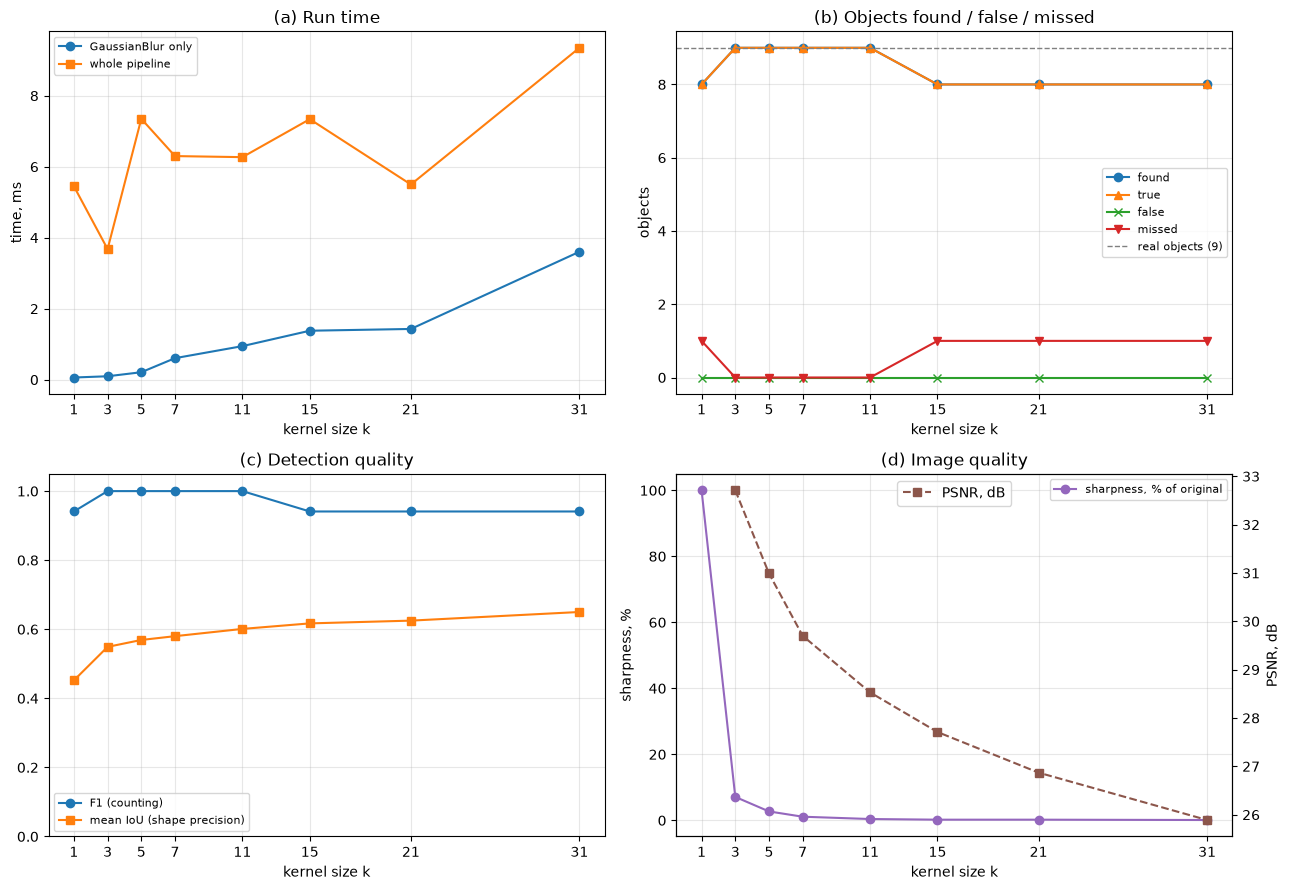

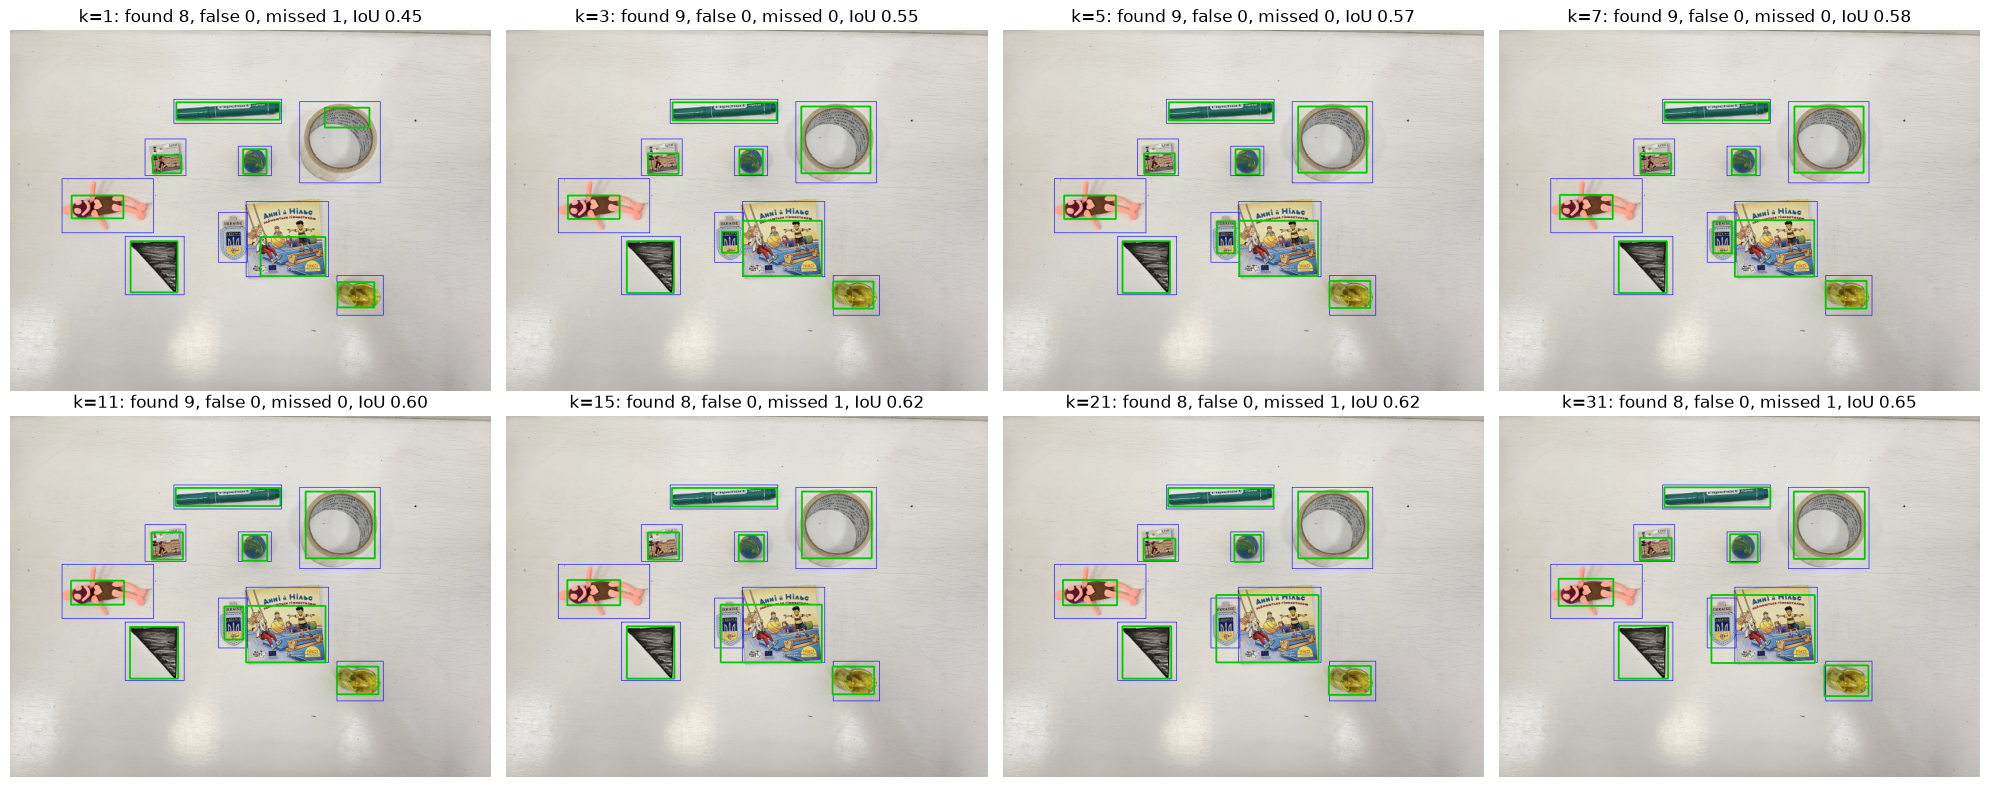

In [5]:
KS, REPS = [1, 3, 5, 7, 11, 15, 21, 31], 20
lap0 = cv2.Laplacian(gray, cv2.CV_64F).var()
rows, results = [], {}

for k in KS:
    t_blur = []
    for _ in range(REPS):                                   # blur time: median of 20 runs
        t0 = time.perf_counter()
        _ = cv2.GaussianBlur(gray, (k, k), 0) if k > 1 else gray.copy()
        t_blur.append((time.perf_counter() - t0) * 1000)
    t_pipe = [run(k)["total_ms"] for _ in range(5)]         # whole pipeline: median of 5 runs
    r = run(k)
    labels, tp, fp, fn, f1, miou = evaluate(r["boxes"])
    results[k] = (r, labels)
    rows.append(dict(k=k, sigma=round(0.3 * ((k - 1) * 0.5 - 1) + 0.8, 2) if k > 1 else 0,
                     blur_ms=round(float(np.median(t_blur)), 3), pipeline_ms=round(float(np.median(t_pipe)), 2),
                     otsu_T=int(r["T"]), found=len(r["boxes"]), true=tp, false=fp, missed=fn,
                     f1=round(f1, 3), mean_iou=round(miou, 3),
                     sharpness_pct=round(100 * cv2.Laplacian(r["blurred"], cv2.CV_64F).var() / lap0, 1),
                     psnr_db=round(cv2.PSNR(gray, r["blurred"]), 2) if k > 1 else None))

hdr = list(rows[0])
print(" | ".join(f"{h:>9s}" for h in hdr))
for row in rows: print(" | ".join(f"{str(row[h]):>9s}" for h in hdr))
with open(RESULTS / "task12_experiment.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=hdr); w.writeheader(); w.writerows(rows)

# --- graphs: result vs parameter ---
k_ = [r["k"] for r in rows]
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ax[0, 0].plot(k_, [r["blur_ms"] for r in rows], "o-", label="GaussianBlur only")
ax[0, 0].plot(k_, [r["pipeline_ms"] for r in rows], "s-", label="whole pipeline")
ax[0, 0].set_ylabel("time, ms"); ax[0, 0].set_title("(a) Run time")
for key, mk in [("found", "o-"), ("true", "^-"), ("false", "x-"), ("missed", "v-")]:
    ax[0, 1].plot(k_, [r[key] for r in rows], mk, label=key)
ax[0, 1].axhline(len(GT), color="gray", ls="--", lw=1, label="real objects (9)")
ax[0, 1].set_ylabel("objects"); ax[0, 1].set_title("(b) Objects found / false / missed")
ax[1, 0].plot(k_, [r["f1"] for r in rows], "o-", label="F1 (counting)")
ax[1, 0].plot(k_, [r["mean_iou"] for r in rows], "s-", label="mean IoU (shape precision)")
ax[1, 0].set_ylim(0, 1.05); ax[1, 0].set_title("(c) Detection quality")
ax[1, 1].plot(k_, [r["sharpness_pct"] for r in rows], "o-", color="tab:purple", label="sharpness, % of original")
ax[1, 1].set_ylabel("sharpness, %"); ax[1, 1].set_title("(d) Image quality")
a2 = ax[1, 1].twinx(); a2.plot(k_[1:], [r["psnr_db"] for r in rows[1:]], "s--", color="tab:brown", label="PSNR, dB")
a2.set_ylabel("PSNR, dB"); a2.legend(loc="upper center")
for a in ax.ravel():
    a.set_xticks(KS); a.set_xlabel("kernel size k"); a.grid(alpha=0.3); a.legend(loc="best", fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS / "task12_graphs.png", dpi=110); plt.show()

# --- what each k does: detections on the image ---
fig, ax = plt.subplots(2, 4, figsize=(20, 8))
for a, k in zip(ax.ravel(), KS):
    r, labels = results[k]
    a.imshow(cv2.cvtColor(draw(r, labels), cv2.COLOR_BGR2RGB)); a.axis("off")
    rr = next(x for x in rows if x["k"] == k)
    a.set_title(f"k={k}: found {rr['found']}, false {rr['false']}, missed {rr['missed']}, IoU {rr['mean_iou']:.2f}")
plt.tight_layout(); plt.savefig(RESULTS / "task12_masks.png", dpi=80); plt.show()